In [44]:
import sys, yaml
sys.path.append("..")

import numpy as np
import torch

In [45]:
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm

In [46]:
from models import TemporalSatCLIPEncoder

In [47]:
encoder = TemporalSatCLIPEncoder(
    ckpt_path="/home/libe2152/projects/temporal-satclip/ckpts/tsatclip-doy-1M.ckpt",
    repo_path="/home/libe2152/projects/temporal-satclip/",
    model_name="tsatclip/doy",
    device="cuda",  # or "cpu"
)

using pretrained moco vit16
using loss function: satclip_loss
using temporal model: True


## Try on one location

In [48]:
lat, lon = 40.0150, -105.2705  # Boulder, Colorado

In [49]:
# Daily timestamps for 2017
dates = pd.date_range("2017-01-01", "2017-12-31", freq="D")
timestamps = dates.astype("datetime64[s]").astype(np.int64)


In [50]:
timestamps

Index([1483228800, 1483315200, 1483401600, 1483488000, 1483574400, 1483660800,
       1483747200, 1483833600, 1483920000, 1484006400,
       ...
       1513900800, 1513987200, 1514073600, 1514160000, 1514246400, 1514332800,
       1514419200, 1514505600, 1514592000, 1514678400],
      dtype='int64', length=365)

In [51]:
lons = np.full(len(timestamps), lon)
lats = np.full(len(timestamps), lat)

embeddings = encoder.encode(lons, lats, posix_timestamp=timestamps)

In [52]:
embeddings

array([[ 0.5250335 ,  1.5280606 , -1.7651113 , ..., -1.0361959 ,
        -1.7338755 ,  0.15708134],
       [ 0.5001639 ,  1.5194061 , -1.7682858 , ..., -1.0507965 ,
        -1.735602  ,  0.14972976],
       [ 0.47559276,  1.5107914 , -1.7712411 , ..., -1.0652767 ,
        -1.7378352 ,  0.14311433],
       ...,
       [ 0.4853651 ,  1.5001266 , -1.7476032 , ..., -0.9269024 ,
        -1.7312845 ,  0.1383236 ],
       [ 0.46628278,  1.4827329 , -1.759269  , ..., -0.9427391 ,
        -1.7268336 ,  0.13662122],
       [ 0.44725823,  1.4655837 , -1.7707824 , ..., -0.9580995 ,
        -1.7229886 ,  0.13519585]], shape=(365, 256), dtype=float32)

### Visualize per channel

In [ ]:
n_dims = embeddings.shape[1]
fig, axes = plt.subplots(n_dims, 1, figsize=(10, 2 * n_dims), sharex=True)

for d, ax in enumerate(axes):
    ax.plot(embeddings[:, d])
    ax.set_title(f"Dimension {d}")

axes[-1].set_xlabel("Day of year")
plt.tight_layout()
plt.show()


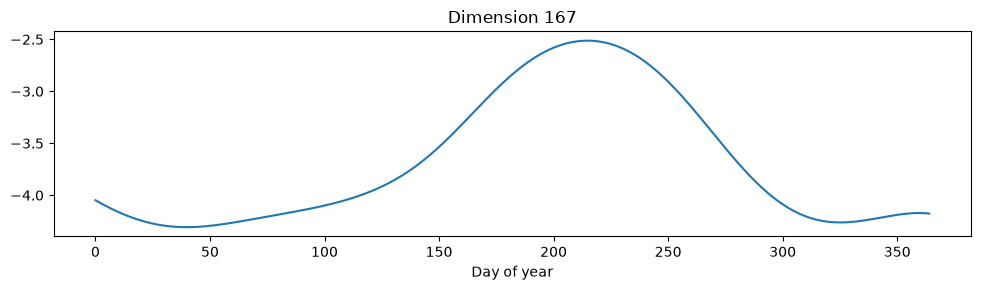

In [60]:
d = 167

plt.figure(figsize=(10, 3))
plt.plot(embeddings[:, d])
plt.title(f"Dimension {d}")
plt.xlabel("Day of year")
plt.tight_layout()
plt.show()

## Sample UAR locations

In [12]:
import geopandas as gpd
from shapely.geometry import Point

world = gpd.read_file("shapefiles/ne_110m_admin_0_countries.shp").union_all()

num_points = 10_000

rng = np.random.default_rng(42)
lons, lats = [], []
while len(lons) < num_points:
    lon = rng.uniform(-180, 180, 50_000)
    lat = rng.uniform(-90, 90, 50_000)
    mask = [world.contains(Point(x, y)) for x, y in zip(lon, lat)]
    lons.extend(lon[mask])
    lats.extend(lat[mask])

lons = np.array(lons[:num_points])
lats = np.array(lats[:num_points])

In [13]:
dates = pd.date_range("2017-01-01", "2017-12-31", freq="D")
timestamps = dates.astype("datetime64[s]").astype(np.int64)  # (365,)
N_days = len(timestamps)
N_locs = len(lons)

In [14]:
lons_rep = torch.from_numpy(np.repeat(lons, N_days)).float()
lats_rep = torch.from_numpy(np.repeat(lats, N_days)).float()
ts_rep   = torch.from_numpy(np.tile(timestamps, N_locs))


In [16]:
BATCH = 4096
all_embs = []

for i in tqdm(range(0, len(lons_rep), BATCH)):
    emb = encoder.encode(lons_rep[i:i+BATCH], lats_rep[i:i+BATCH], posix_timestamp=ts_rep[i:i+BATCH])
    all_embs.append(emb)

100%|██████████| 892/892 [03:49<00:00,  3.88it/s]


In [19]:
all_embs = torch.from_numpy(np.concatenate(all_embs, axis=0))

### Visualize

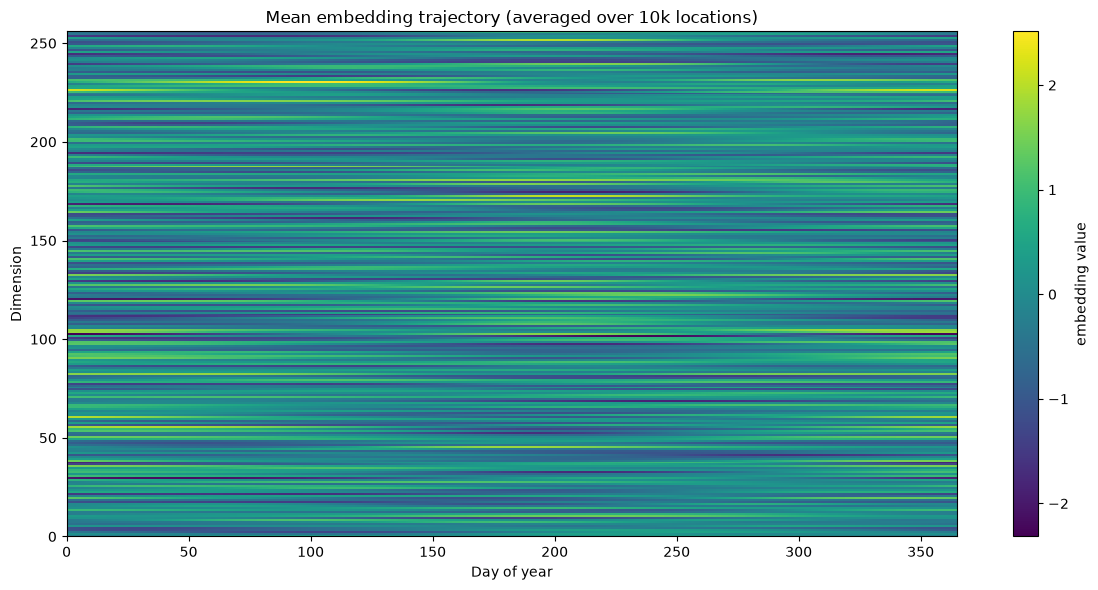

In [22]:
# reshape flat (N_locs*N_days, D) -> (N_locs, N_days, D)
embs = all_embs.numpy().reshape(N_locs, N_days, -1)

# mean across locations -> (N_days, D)
mean_emb = embs.mean(axis=0)

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(mean_emb.T, aspect="auto", interpolation="nearest",
               extent=[0, N_days, 0, mean_emb.shape[1]])
plt.colorbar(im, ax=ax, label="embedding value")
ax.set_xlabel("Day of year")
ax.set_ylabel("Dimension")
ax.set_title("Mean embedding trajectory (averaged over 10k locations)")
plt.tight_layout()
plt.show()


### See if one channel (pick randomly) varies over 1 week, 1 month,...

In [23]:
d=1

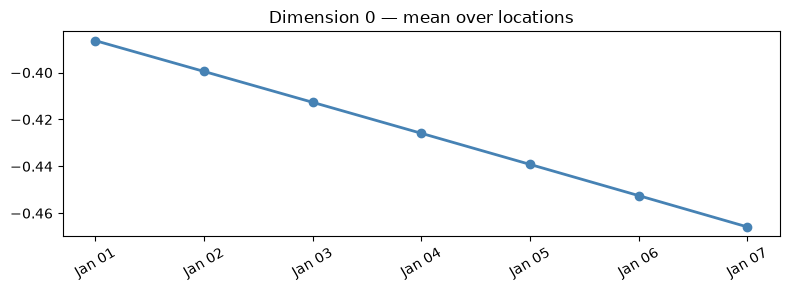

In [26]:
d = 0
week_start = 0

mean_week = embs[:, week_start:week_start+7, d].mean(axis=0)  # (7,)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(mean_week, color="steelblue", linewidth=2, marker="o")
ax.set_xticks(range(7))
ax.set_xticklabels([dates[week_start + i].strftime("%b %d") for i in range(7)], rotation=30)
ax.set_title(f"Dimension {d} — mean over locations")
plt.tight_layout()
plt.show()


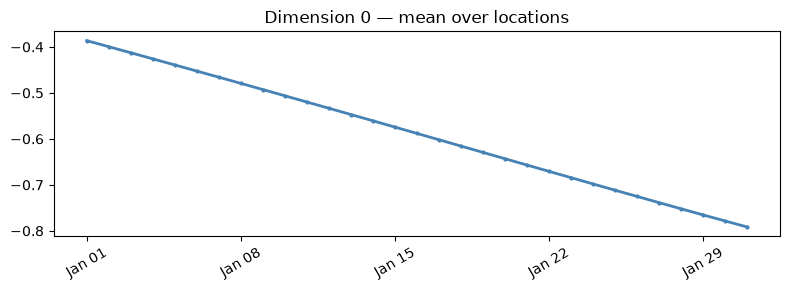

In [31]:
d = 0
month_start = 0

mean_month = embs[:, month_start:month_start+31, d].mean(axis=0)  # (31,)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(mean_month, color="steelblue", linewidth=2, marker="o", markersize=2)
ax.set_xticks(range(31))
ax.set_xticks(
    range(0, 31, 7),
    labels=[dates[month_start + i].strftime("%b %d") for i in range(0, 31, 7)],
    rotation=30
)
ax.set_title(f"Dimension {d} — mean over locations")
plt.tight_layout()
plt.show()


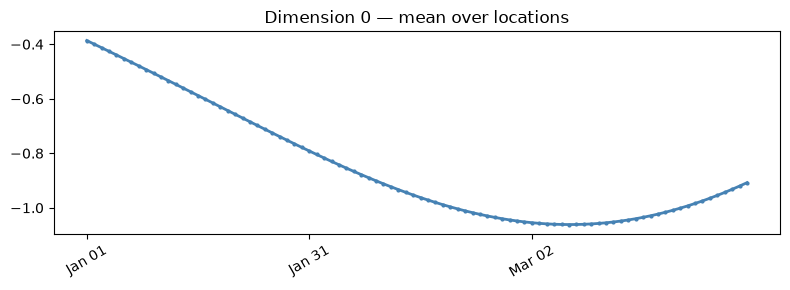

In [ ]:
d = 0
season_start = 0

mean_season = embs[:, season_start:season_start+90, d].mean(axis=0)  # (90,)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(mean_season, color="steelblue", linewidth=2, marker="o", markersize=2)
ax.set_xticks(range(90))
ax.set_xticks(
    range(0, 90, 30),
    labels=[dates[season_start + i].strftime("%b %d") for i in range(0, 90, 30)],
    rotation=30
)
ax.set_title(f"Dimension {d} — mean over locations")
plt.tight_layout()
plt.show()


# Plot average distance between embeddings across various time differences

In [35]:
all_embs = all_embs.reshape(N_locs, N_days, -1)


Text(0.5, 1.0, 'Temporal resolution')

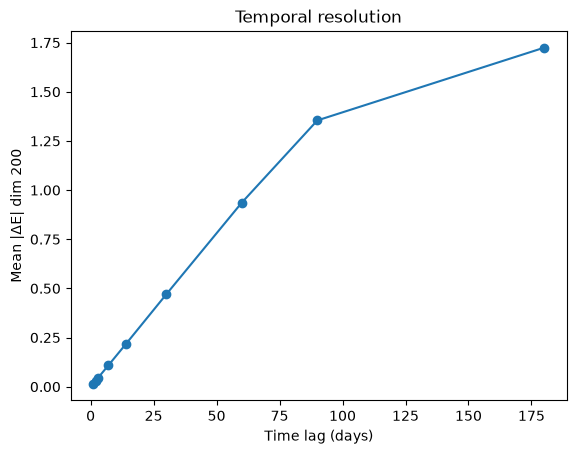

In [39]:
d = 200  # change this to inspect other dimensions

lags = [1, 2, 3, 7, 14, 30, 60, 90, 180]
mean_dists = []
for lag in lags:
    diffs = all_embs[:, lag:, d] - all_embs[:, :-lag, d]  # (N_locs, N_days-lag)
    mean_dists.append(diffs.abs().mean().item())

plt.plot(lags, mean_dists, marker="o")
plt.xlabel("Time lag (days)")
plt.ylabel(f"Mean |ΔE| dim {d}")
plt.title("Temporal resolution")
